# Sprint 1 · Demostración académica con muestras

HU01: fuentes; HU02: normalización y calidad; HU03: características. **Datos sintéticos de desarrollo, caso de estudio real y validación empresarial final pendiente.**

Este notebook es autocontenido dentro del repositorio: biblioteca estándar y `demo/muestras`. No usa la implementación reservada, Supabase ni etiquetas privadas. Los totales globales son resultados anteriores, no conteos recalculados con muestras. Las reproducciones simplificadas se identifican expresamente. Recorrido sugerido: cinco o seis minutos.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timedelta, timezone
from decimal import Decimal, ROUND_HALF_UP
from html import escape
import csv, hashlib, json, math, sys
sys.dont_write_bytecode = True
REPO = next((candidate for p in (Path.cwd(), *Path.cwd().parents)
             for candidate in (p, p / 'sistema-deteccion')
             if (candidate / 'demo/muestras/manifest.json').is_file()), None)
if REPO is None:
    raise RuntimeError('Abra el notebook desde el repositorio o demo/notebook.')
MUESTRAS = REPO / 'demo/muestras'
results = json.loads((MUESTRAS/'resultados-verificados.json').read_text(encoding='utf-8'))
manifest = json.loads((MUESTRAS/'manifest.json').read_text(encoding='utf-8'))
for name, info in manifest['files'].items():
    assert hashlib.sha256((MUESTRAS/name).read_bytes()).hexdigest() == info['sample_sha256']

class Rich:
    def __init__(self, value, kind='html'): self.value, self.kind = value, kind
    def _repr_mimebundle_(self, include=None, exclude=None):
        return {'text/html' if self.kind=='html' else 'image/svg+xml': self.value,
                'text/plain': 'Tabla o gráfico educativo'}
def table(rows):
    rows=list(rows); columns=list(rows[0]) if rows else []
    head=''.join('<th style="padding:8px;background:#e8f3f0">'+escape(k)+'</th>' for k in columns)
    body=''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #d5e1e7">'+escape('Ausente' if r[k] is None else str(r[k]))+'</td>' for k in columns)+'</tr>' for r in rows)
    return Rich('<div style="overflow:auto"><table style="background:white;color:#162b3b;font:14px system-ui;border-collapse:collapse"><tr>'+head+'</tr>'+body+'</table></div>')
def bars(title, labels, values):
    height=60+45*len(values); maximum=max(values) or 1
    parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="860" height="{height}" viewBox="0 0 860 {height}" role="img">', '<rect width="100%" height="100%" fill="white"/>', '<text x="15" y="25" font-family="sans-serif" font-size="16">'+escape(title)+'</text>']
    for i,(label,value) in enumerate(zip(labels,values)):
        y=45+45*i; length=420*value/maximum
        parts += [f'<text x="15" y="{y+17}" font-family="sans-serif" font-size="13">'+escape(label)+'</text>',f'<rect x="260" y="{y}" width="{length}" height="24" fill="#168775"/>',f'<text x="{272+length}" y="{y+17}" font-family="sans-serif" font-size="13">{value:,}</text>']
    return Rich(''.join(parts)+'</svg>','svg')
files={'endpoint':'endpoint_file_logs.csv','cloud':'cloud_audit_export.csv','transfer':'transfer_activity.csv'}
raw={}
for source,name in files.items():
    with (MUESTRAS/name).open(encoding='utf-8',newline='') as f: raw[source]=list(csv.DictReader(f))
print('Preparación offline lista. No se carga la implementación interna.')

Preparación offline lista. No se carga la implementación interna.


## HU01 — Tres fuentes heterogéneas

Se leen **muestras pequeñas**, no las 20,000 filas originales. Mostramos cinco registros por fuente; el total global 20,000 es el resultado previo documentado.

In [2]:
table([{'Fuente':s,'Filas de muestra':len(raw[s]),'Total previo de desarrollo':n,'Columnas':len(raw[s][0])} for s,n in [('endpoint',10000),('cloud',6500),('transfer',3500)]])

Fuente,Filas de muestra,Total previo de desarrollo,Columnas
endpoint,12,10000,11
cloud,9,6500,10
transfer,6,3500,10


### endpoint: cinco registros y sus columnas originales

In [3]:
table(raw['endpoint'][:5])

id_evento,FECHA,USUARIO,PC,ACCION,ARCHIVO,TAMANO,UNIDAD,RUTA_ORIGEN,RUTA_DESTINO,APP
ENDPOINT-0001195,2026-09-01 07:00:00,u-003,LAB-PC-03,Editar,project_endpoint-0001698_asset_000.zip,20.48,MB,C:\Projects\project_endpoint-0001698_asset_000.zip,\\backups.internal\projects,admin-console
ENDPOINT-0004839,01/09/2026 07:00:48,u-003,LAB-PC-03,Copia,project_endpoint-0001698_asset_001.sql,8559.61,KB,C:\Projects\project_endpoint-0001698_asset_001.sql,\\backups.internal\projects,admin-console
ENDPOINT-0007263,01/09/2026 07:01:36,u-003,LAB-PC-03,COPY,project_endpoint-0001698_asset_002.zip,8820.86,KB,C:\Projects\project_endpoint-0001698_asset_002.zip,\\backups.internal\projects,admin-console
ENDPOINT-0006844,2026-09-01 07:02:24,emp003,LAB-PC-03,COPY,project_endpoint-0001698_asset_003.bak,6244024,B,C:\Projects\project_endpoint-0001698_asset_003.bak,\\backups.internal\projects,admin-console
ENDPOINT-0001484,2026-09-01 07:03:12,emp003,LAB-PC-03,OPEN,project_endpoint-0001698_asset_004.bak,4.86,MB,C:\Projects\project_endpoint-0001698_asset_004.bak,\\backups.internal\projects,admin-console


### cloud: cinco registros y sus columnas originales

In [4]:
table(raw['cloud'][:5])

recordId,eventTime,actorId,activity,resourceName,sizeBytes,sourceType,destination,clientApp,category
CLOUD-0000769,2026-09-01T07:18:00-05:00,u-018,DOWNLOAD,project_cloud-0000642_asset_000.log,8019605,CORPORATE_REPOSITORY,backups.internal,backup-client,INTERNAL
CLOUD-0002263,2026-09-01T07:18:58-05:00,U-018,Subir,project_cloud-0000642_asset_001.zip,10487015,CORPORATE_REPOSITORY,backups.internal,backup-client,PUBLIC
CLOUD-0003736,2026-09-01T07:19:56-05:00,u-018,Subir,project_cloud-0000642_asset_002.log,17043110,CORPORATE_REPOSITORY,backups.internal,backup-client,INTERNAL
CLOUD-0005902,2026-09-01T07:20:54-05:00,u-018,Subir,project_cloud-0000642_asset_003.log,2339825,CORPORATE_REPOSITORY,backups.internal,backup-client,INTERNAL
CLOUD-0003515,2026-09-01T07:21:52-05:00,U-018,Subir,project_cloud-0000642_asset_004.log,8781310,CORPORATE_REPOSITORY,backups.internal,backup-client,INTERNAL


### transfer: cinco registros y sus columnas originales

In [5]:
table(raw['transfer'][:5])

TransferId,TimeStamp,Account,PCName,TransferMethod,Object,Size,Destination,Result,Classification
TRANSFER-0001812,09/01/2026 08:57:00 AM,STAFF-018,LAB-PC-18,EMAIL_ATTACHMENT,project_transfer-0002403_asset_000.zip,5180.66 KB,backups.internal,ALLOWED,INTERNAL
TRANSFER-0000634,09/01/2026 08:57:56 AM,STAFF-018,LAB-PC-18,COPY,project_transfer-0002403_asset_001.bak,16492881 bytes,backups.internal,ALLOWED,INTERNAL
TRANSFER-0003130,09/01/2026 08:58:52 AM,STAFF-018,LAB-PC-18,Adjuntar,project_transfer-0002403_asset_002.zip,25.94 MB,backups.internal,ALLOWED,PUBLIC
TRANSFER-0000394,09/01/2026 08:59:48 AM,STAFF-018,LAB-PC-18,Adjuntar,project_transfer-0002403_asset_003.sql,24033.0 KB,backups.internal,ALLOWED,PUBLIC
TRANSFER-0002950,09/01/2026 09:00:44 AM,STAFF-018,LAB-PC-18,Copia,project_transfer-0002403_asset_004.bak,1.77 MB,backups.internal,ALLOWED,CONFIDENTIAL


## HU02 — Reproducción pedagógica limitada

La siguiente función **no es el normalizador de producción**: aplica solo las equivalencias necesarias de los tres ejemplos conocidos y del destino ausente. Su resultado se contrasta con la proyección normalizada previamente verificada. No trata el dataset completo ni pretende reproducir todas las reglas de calidad.

In [6]:
with (MUESTRAS/'employees_directory.csv').open(encoding='utf-8',newline='') as f:
    employees=list(csv.DictReader(f))
aliases={r[k].casefold():r['EmployeeCode'] for r in employees
         for k in ('EmployeeCode','AccountAlias','TransferAlias')}
FIELDS={'endpoint':('id_evento','USUARIO','FECHA','TAMANO','ACCION','RUTA_DESTINO'),
        'cloud':('recordId','actorId','eventTime','sizeBytes','activity','destination'),
        'transfer':('TransferId','Account','TimeStamp','Size','TransferMethod','Destination')}
LIMA=timezone(timedelta(hours=-5))
def parse_time(value, source):
    t=datetime.strptime(value,'%m/%d/%Y %I:%M:%S %p') if source=='transfer' else datetime.fromisoformat(value.replace('Z','+00:00'))
    return t.replace(tzinfo=LIMA) if t.tzinfo is None else t
def educational_example(row,source):
    _,actor,when,size,operation,destination=FIELDS[source]
    value=row[size];unit=row.get('UNIDAD','bytes')
    if source=='transfer': value,unit=value.split()
    factor={'bytes':1,'b':1,'kb':1024,'mb':1048576}[unit.casefold()]
    size_bytes=int((Decimal(value)*factor).quantize(Decimal(1),rounding=ROUND_HALF_UP))
    operations={'editar':'file_modify','download':'file_download','email_attachment':'email_attachment',
                'sincronizar':'cloud_sync'}
    return {'user_id':aliases[row[actor].casefold()],
            'timestamp':parse_time(row[when],source).astimezone(timezone.utc).isoformat(),
            'file_size_bytes':size_bytes,'operation':operations[row[operation].casefold()],
            'destination_path':row[destination] or None}
comparison=[]
for sample in results['samples']:
    source=sample['source']; key=FIELDS[source][0]
    row=next(r for r in raw[source] if r[key]==sample['event_id'])
    actual=educational_example(row,source);expected=sample['normalized']
    assert datetime.fromisoformat(actual['timestamp'])==datetime.fromisoformat(expected['timestamp'])
    assert all(actual[k]==expected[k] for k in ('user_id','file_size_bytes','operation','destination_path'))
    comparison.append({'Evento':sample['event_id'],'Actor original':row[FIELDS[source][1]],
                       'Actor común':actual['user_id'],'Fecha UTC':actual['timestamp'],
                       'Bytes':actual['file_size_bytes'],'Operación':actual['operation']})
table(comparison)

Evento,Actor original,Actor común,Fecha UTC,Bytes,Operación
CLOUD-0000769,u-018,EMP018,2026-09-01T12:18:00+00:00,8019605,file_download
ENDPOINT-0001195,u-003,EMP003,2026-09-01T12:00:00+00:00,21474836,file_modify
TRANSFER-0001812,STAFF-018,EMP018,2026-09-01T13:57:00+00:00,5304996,email_attachment


In [7]:
source='cloud'; row=next(r for r in raw[source] if r['recordId']=='CLOUD-0000745')
actual=educational_example(row,source);expected=results['missing_destination_example']
assert actual['destination_path'] is None and actual['file_size_bytes']==expected['file_size_bytes']
table([{'Evento':row['recordId'],'Destino original':row['destination'],
        'Destino común':actual['destination_path'],'Resultado previo':'Válido con advertencia MISSING_DESTINATION'}])

Evento,Destino original,Destino común,Resultado previo
CLOUD-0000745,,Ausente,Válido con advertencia MISSING_DESTINATION


## Calidad: duplicados y cuarentena

Las muestras conservan dos ocurrencias idénticas del evento CLOUD-0002868. Un ejemplo duplicado no equivale a recontar los 358 globales. Los motivos de rechazo siguientes proceden de resultados verificados, no de una nueva ejecución completa de HU02.

In [8]:
pair=[r for r in raw['cloud'] if r['recordId']==results['duplicate_event_id']]
assert len(pair)==2 and pair[0]==pair[1]
table([{'Evento':r['recordId'],'Ocurrencia en muestra':i+1,'Payload idéntico':True} for i,r in enumerate(pair)])

Evento,Ocurrencia en muestra,Payload idéntico
CLOUD-0002868,1,True
CLOUD-0002868,2,True


In [9]:
table([{'Evento':s['event_id'],'Fecha original':s['raw_timestamp'],'Motivo previo':', '.join(i['code'] for i in s['issues'])} for s in results['quarantine_examples']])

Evento,Fecha original,Motivo previo
CLOUD-0000288,fecha_desconocida,INVALID_TIMESTAMP
TRANSFER-0002761,fecha_desconocida,INVALID_TIMESTAMP


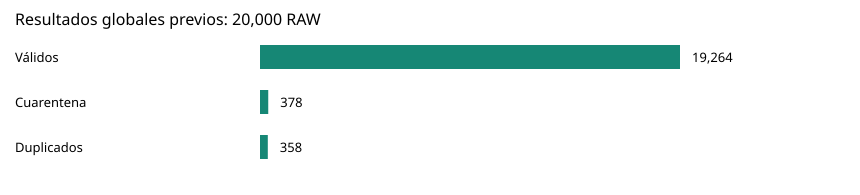

In [10]:
summary=results['summary']
assert summary['normalized']+summary['quarantine']==summary['canonical']
assert summary['canonical']+summary['duplicates']==summary['raw']==20000
bars('Resultados globales previos: 20,000 RAW', ['Válidos','Cuarentena','Duplicados'],
     [summary['normalized'],summary['quarantine'],summary['duplicates']])

## HU03 — Ventana EMP002: seis eventos verificados

7 de septiembre, 14–15 UTC = 09–10 Lima. Intervalos [inicio, fin), horas de 60 minutos. Se usan solo canónicos válidos. Leemos seis resultados previos; **no recalculamos ni persistimos las 2,102 ventanas**.

In [11]:
events=results['window_events']
assert len(events)==6
table([{'Evento':e['source_event_id'],'Hora UTC':e['timestamp'],'Operación':e['operation'],
        'Bytes':e['file_size_bytes'],'Destino':e['destination_path']} for e in events])

Evento,Hora UTC,Operación,Bytes,Destino
ENDPOINT-0003959,2026-09-07T14:06:00Z,file_copy,607478,/srv/quality/exports
ENDPOINT-0007483,2026-09-07T14:06:45Z,file_access,1499167,/srv/quality/exports
ENDPOINT-0005471,2026-09-07T14:07:30Z,file_modify,296708,/srv/quality/exports
ENDPOINT-0005733,2026-09-07T14:08:15Z,file_access,1235643,/srv/quality/exports
ENDPOINT-0003056,2026-09-07T14:09:00Z,file_copy,597688,/srv/quality/exports
ENDPOINT-0008732,2026-09-07T14:09:45Z,file_copy,449270,/srv/quality/exports


In [12]:
# Cálculo pedagógico de una sola ventana, contrastado con su vector previo.
employee=next(r for r in employees if r['EmployeeCode']=='EMP002')
work_start=datetime.strptime(employee['WorkStart'],'%H:%M').time()
work_end=datetime.strptime(employee['WorkEnd'],'%H:%M').time()
def off_hours(event):
    local=datetime.fromisoformat(event['timestamp'].replace('Z','+00:00')).astimezone(LIMA)
    return local.weekday()>=5 or not work_start<=local.time()<work_end
n=len(events);total=sum(e['file_size_bytes'] for e in events)
off=sum(off_hours(e) for e in events);missing=sum(e['destination_path'] is None for e in events)
operations=Counter(e['operation'] for e in events)
vector={'operation_count':n,'total_bytes':total,'operations_per_hour':n*60/60,
        'off_hours_count':off,'off_hours_ratio':off/n,
        'distinct_destination_count':len({e['destination_path'] for e in events if e['destination_path'] is not None}),
        'missing_destination_count':missing,'missing_destination_ratio':missing/n,
        'download_count':operations['file_download'],'upload_count':operations['web_upload'],
        'usb_copy_count':operations['usb_copy']}
assert total==4685954 and vector==results['window']['features']
assert len(vector)==11 and all(math.isfinite(v) and v>=0 for v in vector.values())
print('Suma:', ' + '.join(str(e['file_size_bytes']) for e in events), '=', total, 'bytes')
table([{'Característica':k,'Cálculo pedagógico':vector[k],'Resultado previo':results['window']['features'][k]} for k in results['window']['feature_order']])

Suma: 607478 + 1499167 + 296708 + 1235643 + 597688 + 449270 = 4685954 bytes


Característica,Cálculo pedagógico,Resultado previo
operation_count,6,6
total_bytes,4685954,4685954
operations_per_hour,6.0,6.0
off_hours_count,0,0
off_hours_ratio,0.0,0.0
distinct_destination_count,1,1
missing_destination_count,0,0
missing_destination_ratio,0.0,0.0
download_count,0,0
upload_count,0,0


## Resultados finales y separación temporal

Los totales siguientes son resultados previos, no extrapolaciones de las muestras. Ventanas vacías omitidas; horarios en Lima; metadatos e identidades fuera del vector. Cualquier modelo o escalado aprendido se ajustará solo con entrenamiento, en una etapa posterior autorizada.

In [13]:
parts=results['partitions']
assert parts=={'train':1334,'validation':487,'test':281} and sum(parts.values())==2102
table([{'Partición':p,'Días de septiembre (Lima)':d,'Ventanas previas':parts[p]} for p,d in [('train','1–20'),('validation','21–25'),('test','26–30')]])

Partición,Días de septiembre (Lima),Ventanas previas
train,1–20,1334
validation,21–25,487
test,26–30,281


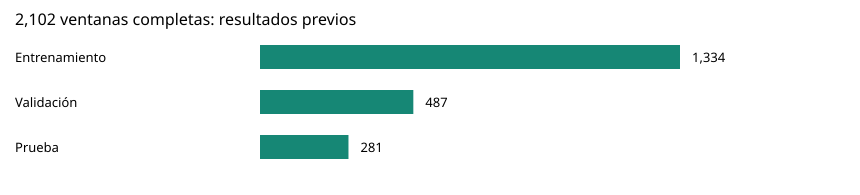

In [14]:
bars('2,102 ventanas completas: resultados previos',['Entrenamiento','Validación','Prueba'],[parts[p] for p in ('train','validation','test')])

## Conclusión

Se demostró preparación de datos, no detección de fugas. El modelo no fue entrenado en Sprint 1. Datos sintéticos y validación empresarial final pendiente. P18 FAIL/P15 PARTIAL avanzados congelados, sin uso en este recurso; aceptación académica formal pendiente.

Este notebook es una adaptación pedagógica del recurso original: **no importa módulos internos ni ejecuta el pipeline completo**. Procedencia y huellas: `demo/muestras/manifest.json`. La duración de cinco o seis minutos es propuesta; requiere ensayo oral auténtico.